In [30]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [31]:
data = pd.read_csv("cifar-10.csv")

print(data.head())
print(data.shape)

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [32]:
x= data.drop("label", axis=1).values
y = data["label"].values

In [33]:
x = x.reshape(-1,3,32,32)

#-1 = Automatically calculate the number of images (50,000).
#3 = Three colour channels (RGB).
#32 = Image height.
#32 = Image width.
x = x.transpose(0,2,3,1)
#(Number of images, Channels, Height, Width)

In [34]:
x = x.astype("float32")/255.0

X_train,X_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y#important
)

print("Training", X_train.shape)
print("Testing", X_test.shape)

Training (40000, 32, 32, 3)
Testing (10000, 32, 32, 3)


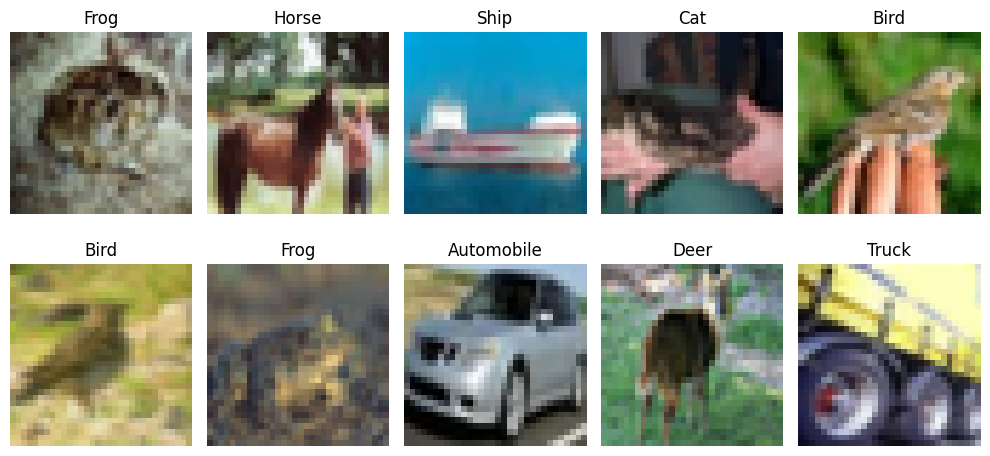

In [35]:
classes = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
           "Dog", "Frog", "Horse", "Ship", "Truck"]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[i])
    plt.title(classes[int(y_train[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [36]:
model = keras.Sequential([
    keras.layers.Conv2D(32,(3,3), activation="relu", input_shape=(32,32,3)),
    keras.layers.MaxPooling2D((2,2)),#pooling window size
    #no of filter,filter size,activation,inputshape
    keras.layers.Conv2D(64,(3,3), activation="relu"),#Extracts image features (edges, shapes, patterns)
    keras.layers.MaxPooling2D((2,2)),#Reduces image dimensions

    keras.layers.Flatten(),#Converts feature maps into a 1D vector
    keras.layers.Dense(128,activation="relu"),#Learns to classify extracted features
    keras.layers.Dense(10,activation="softmax")#Predicts one of 10 classes
])

model.summary()

C:\Users\Avadhut\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [38]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_data=(X_test,y_test)
)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.4638 - loss: 1.4871 - val_accuracy: 0.5614 - val_loss: 1.2352
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.6032 - loss: 1.1277 - val_accuracy: 0.6281 - val_loss: 1.0798
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.6574 - loss: 0.9782 - val_accuracy: 0.6517 - val_loss: 1.0141
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.6984 - loss: 0.8768 - val_accuracy: 0.6594 - val_loss: 0.9929
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.7242 - loss: 0.7944 - val_accuracy: 0.6878 - val_loss: 0.9089
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.7494 - loss: 0.7182 - val_accuracy: 0.6965 - val_loss: 0.9052
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.7729 - loss: 0.6501 - val_accuracy: 0.6870 - val_loss: 0.9296
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.7988 - los

In [39]:
loss,accuracy = model.evaluate(X_test,y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6909 - loss: 1.0284
Test Loss: 1.028408169746399
Test Accuracy: 0.6909000277519226


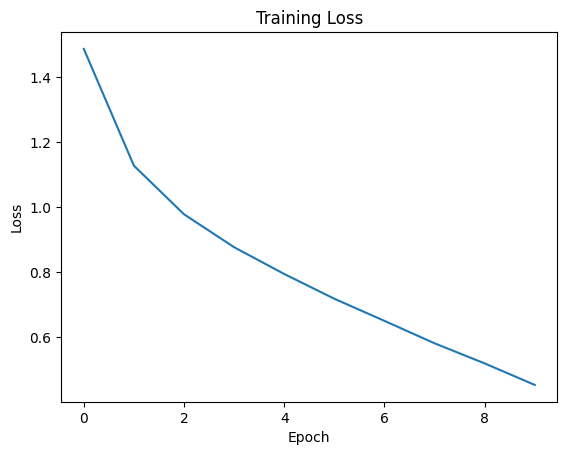

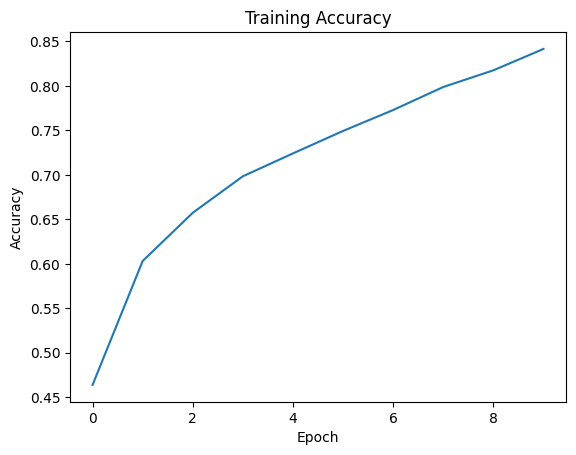

In [40]:
plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


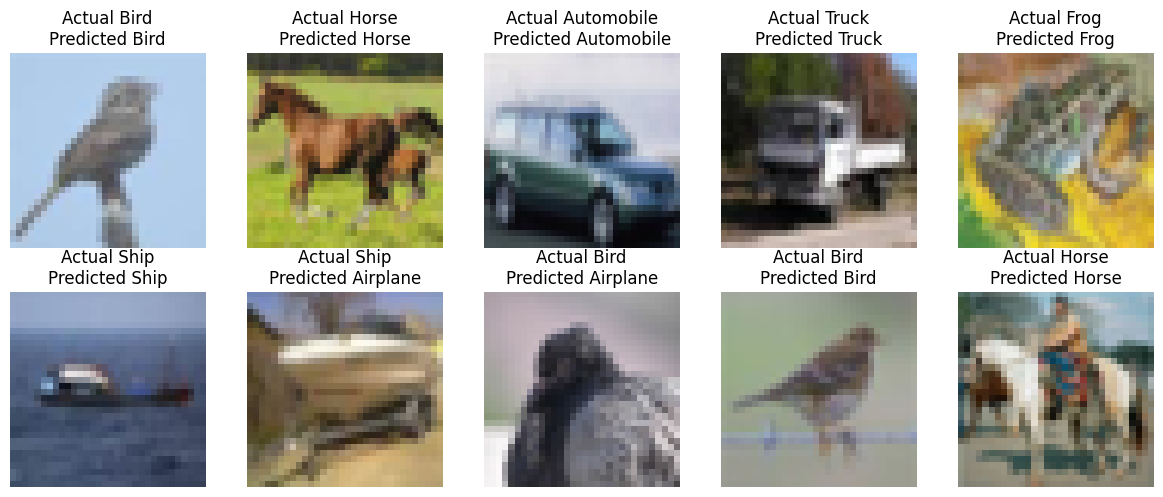

In [41]:
classes = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
           "Dog", "Frog", "Horse", "Ship", "Truck"]

predictions = model.predict(X_test[:10])

plt.figure(figsize=(12,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i])

    actual = classes[int(y_test[i])]
    predicted = classes[np.argmax(predictions[i])]

    plt.title(f"Actual {actual}\nPredicted {predicted}")
    plt.axis("off")

plt.tight_layout()    
plt.show()